In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.special import eval_legendre
from scipy.optimize import root_scalar
from scipy.interpolate import interp1d

In [2]:
#Constants-------
G_SI = 6.67430e-11       # m^3 kg^-1 s^-2
c_SI = 299792458.0       # m s^-1
M_sun = 1.98847e30       # kg
M_p = 100*M_sun         #Physical Black hole mass
D_l = 3.086 * 1e22       #source distance (m)
L_m = G_SI*M_p/c_SI**2   #rescaling length
t_m = G_SI*M_p/c_SI**3   #rescaling time

#Parameters------

M = 1       #Dimensionless black hole mass. All other parameters are scaled by the physical mass.
mu = 1e-7   #String tension
E = 5*M     #String energy parameter
l = np.array([2,4,6,8])     #Mode
m = 0       #Mode



Nt = 20000  #time values 
Nr = 2000   #radial values

#Variables-------

#Coordinates
theta = np.pi/2     #plane of motion        

tau_min = 0     #worldsheet time
tau_max = np.arccos(M/np.sqrt(M**2 + E**2))
tau = np.linspace(tau_min, tau_max * (1.0 - 1e-9), 1000)

d = (np.sqrt(M**2 + E**2) - M)/E
t = np.array(E*tau + 2*M*np.log(np.abs((np.tan(tau/2) + d)/(np.tan(tau/2) - d))))       #physical time

r = np.array(M + np.sqrt(M**2 + E**2)*np.cos(tau))      #physical radius

sort_indices = np.argsort(t)  # finds the order to put time from smallest to largest
t = t[sort_indices]           # reorganizes the time values
r = r[sort_indices]  


epsilon = 0.02 #just above horizon
r_min = 2.0 * M + epsilon    #horizon

#tortoise coordinate
r_star_min = r_min + 2 * M * np.log(r_min / (2.0 * M) - 1.0)  
r_star_max = 100 * M + 2 * M * np.log(100 * M / (2.0 * M) - 1.0)

r_star = np.linspace(r_star_min, r_star_max, Nr)
dr_star = r_star[1] - r_star[0]  
dt = 0.5 * dr_star

sigma = 6*dr_star   #gaussian parameter

#reconvert r_star to r
def get_r_from_r_star(r_star_val, M):

  res = root_scalar(
      lambda r: r_star_val - (r + 2 * M * np.log(r / (2.0 * M) - 1.0)),
      bracket=[2.0 * M + 1e-4, r_star_val + 10.0 * M],
  )
  return res.root


r_i = np.array([get_r_from_r_star(rs, M) for rs in r_star])
r_dot_arg = np.maximum(0.0, E**2 - r_i**2 * (1.0 - 2.0 * M / r_i))
r_dot = np.sqrt(r_dot_arg)

f = 1-2*M/r_i   #schwarzschild term
f_p = 2*M/r_i**2

r_s = r_i[-1]

#cosmic string motion
def string_pos(t_current, t_array, r_array):
    idx = np.abs((t_current - t_array)).argmin()
    return r_array[idx]

r_obs = np.array([100*M, 125*M, 150*M, 200*M])
obs_idx = [np.argmin(np.abs(r_i - val)) for val in r_obs]

#Angular parameters
gamma_1d= (l-1)*(l+2) 
gamma = gamma_1d[:,np.newaxis]
lam = gamma+ 6*M/r_i

In [3]:
#Zerilli Potential

V_even = 1/lam**2 * (gamma**2 * ((gamma+2)/r_i**2 + M/r_i**3) + 36*M**2/r_i**4*(gamma + 2*M/r_i))
V_z = f*V_even

#Source term

P_l = eval_legendre(l, np.cos(theta))
Y_l_1d = np.sqrt((2*l+1)/(4*np.pi)) * P_l
Y_l= Y_l_1d[:,np.newaxis]
K_1 = (32*np.pi**2 * mu * Y_l) / (E * lam) 
K_2 = gamma*(gamma-2) + 12*(gamma-3)*M/r_i + 84*M**2/r_i**2

A_l = K_1 * (lam*f*r_i/gamma + 1/(gamma+2) * ((24*f*M*r_dot**2)/(lam*r_i**2) - 6*f**2*r_i - r_i*f*K_2/lam))

B_l = K_1 * (2 * r_i**2 * f**2)/(gamma + 2)


def del_r(r, r_s, sigma):      #Assuming a narrow gaussian
    z = (r-r_s) / sigma
    return np.exp(-0.5 * z**2) / (np.sqrt(2.0 * np.pi) * sigma)

def del_p_r(r, r_s, sigma):
    delta = del_r(r, r_s, sigma)
    return -(r - r_s) / sigma**2 * delta

r_s0 = string_pos(0, t, r)
S_even = A_l*del_r(r_i, r_s0, sigma) - B_l*del_p_r(r_i, r_s0,sigma)
S = -f*S_even

In [4]:
#Zerilli equation
# d^2 psi/dt^2 = d^2psi/dr_star^2 - fV_even psi - fS_even

nummodes = len(l)
psi_prev = np.zeros((nummodes, Nr))     # past values
psi_curr = np.zeros((nummodes, Nr))     # current values
psi_next = np.zeros((nummodes, Nr))     # future values
psi_next = 0.5 * (dt**2) * S
psi_ext = np.zeros((len(l), Nt, len(obs_idx)))
psi_prev = psi_curr.copy()   # Past becomes what was zero
psi_curr = psi_next.copy()   # Current becomes our new state

In [5]:
target_rs_values = [5.5, 4.5, 3.5, 2.5]

wave_snapshots = {}

for n in range(0, Nt):

    t_current = n*dt
    r_s = string_pos(t_current, t, r)
    
    
    S_even = A_l*del_r(r_i, r_s, sigma) - B_l*del_p_r(r_i, r_s,sigma)
    S = -f*S_even
    
    d2psi_drstar2 = (
    psi_curr[:, 2:] - 2 * psi_curr[:, 1:-1] + psi_curr[:, :-2]) / dr_star**2
        
    V_z_term = V_z[:, 1:-1] * psi_curr[:, 1:-1]
        
    psi_next[:, 1:-1] = (
      2.0 * psi_curr[:, 1:-1]
      - psi_prev[:, 1:-1]
      + dt**2 * (d2psi_drstar2 - V_z_term + S[:, 1:-1]))
    
    psi_next[:, 0] = psi_curr[:, 0] + (dt / dr_star) * (psi_curr[:, 1] - psi_curr[:, 0])
    psi_next[:, -1] = psi_curr[:, -1] - (dt / dr_star) * (
    psi_curr[:, -1] - psi_curr[:, -2])

    psi_ext[:, n, :] = psi_curr[:, obs_idx]
    psi_prev = psi_curr.copy()
    psi_curr = psi_next.copy()
    for target in target_rs_values:
        if target not in wave_snapshots and r_s <= target:
            wave_snapshots[target] = (r_s, psi_curr.copy())
            print(f" String reached r_s = {r_s:.3f}")
    

 String reached r_s = 5.490
 String reached r_s = 4.496
 String reached r_s = 3.493
 String reached r_s = 2.496


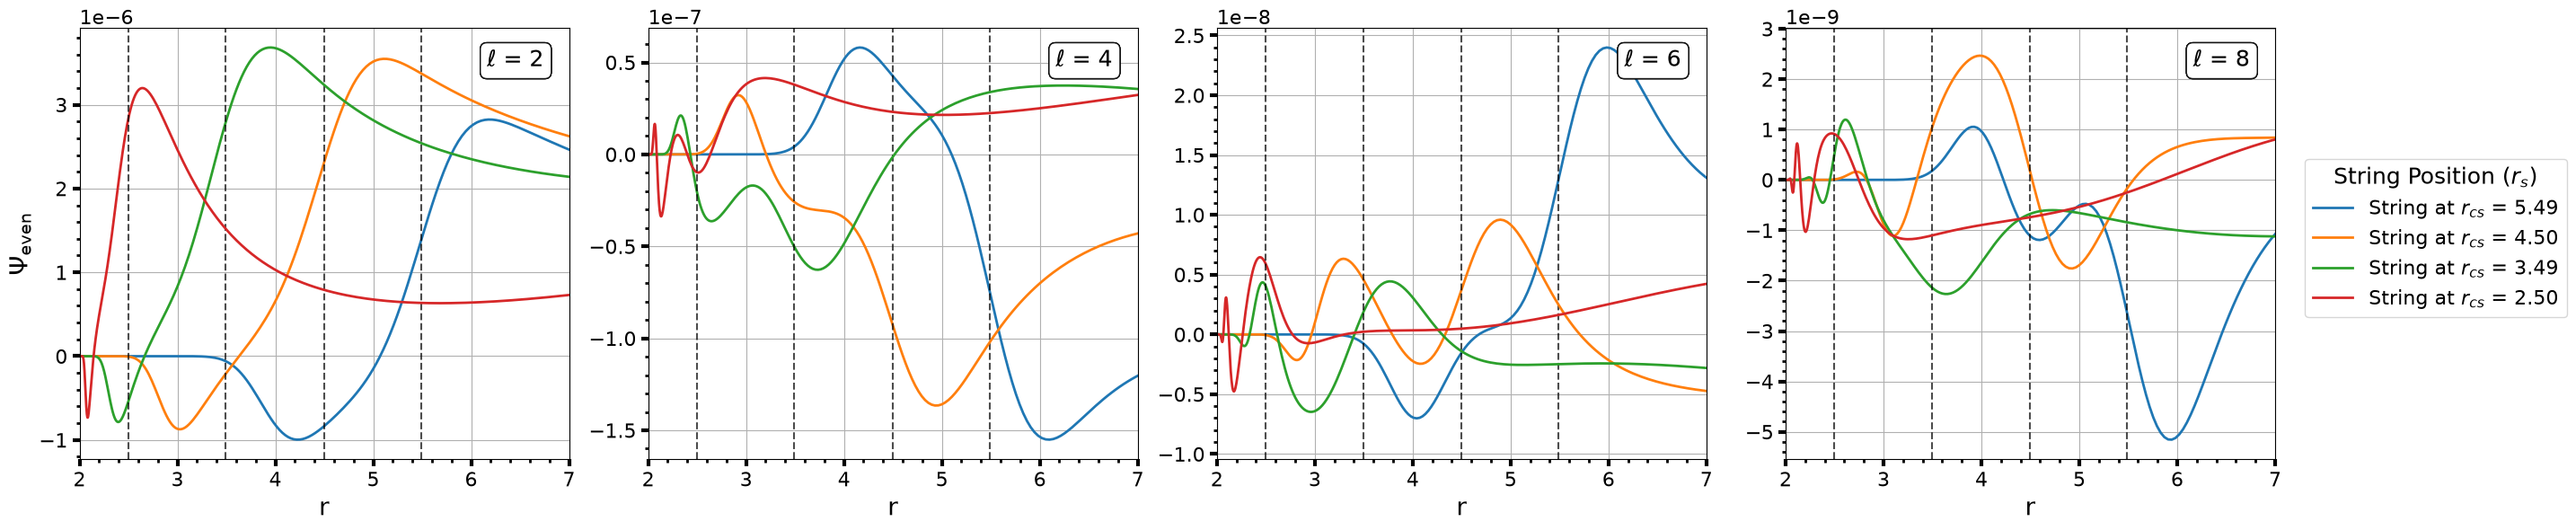

In [6]:
fig, axes = plt.subplots(1, 4, squeeze=False, figsize=(32, 6))
axes = axes.flatten()
for idx, l_val in enumerate(l):
    ax = axes[idx]
    for target, (rs, wave_profile) in wave_snapshots.items():

        ax.plot(r_i, wave_profile[idx], label=f"String at $r_{{cs}}$ = {rs:.2f}", linewidth=2)
        ax.axvline(rs, linestyle = '--', color = 'black', linewidth = 1.5, alpha = 0.7)
        ax.text(
        0.95, 0.95,                     
        f"$\\ell$ = {l[idx]}",
        transform=ax.transAxes,         
        fontsize=18,
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            edgecolor="black",
            alpha=0.8
            ))
        ax.set_xlabel("r", fontsize = 20)
        ax.minorticks_on()
        ax.tick_params(which = 'minor', width = 2, length = 3)
        ax.tick_params(width = 3, length = 6, labelsize = 16)
        axes[0].set_ylabel("$\\Psi_{\\rm even}$", fontsize = 20)
        ax.grid(True)
        ax.set_xlim(2, 7)
        
        ax.yaxis.get_offset_text().set_fontsize(16)  
#fig.supylabel("$\\Psi_{\\rm even}$", fontsize = 20)
plt.tight_layout(rect=[0, 0, 0.80, 1])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, 
    loc='center left', 
    bbox_to_anchor=(0.80, 0.55), 
    title="String Position ($r_s$)",
    title_fontsize=18,
    fontsize=16
)

In [7]:
t_sim = np.arange(Nt) * dt

def psi_at_infinity(t_sim, r_obs, psi_ext, l_modes):
    #using 1/r polynomial fitting
    num_l = len(l_modes)
    Nt = len(t_sim)


    r_obs_max = r_obs[-1]
    r_star_max = r_obs_max + 2.0 * M * np.log(r_obs_max / (2.0 * M) - 1.0)
    u_global = t_sim - r_star_max

    psi_even_inf = np.zeros((num_l, Nt))
    psi_u_grid = np.zeros((len(r_obs), num_l, Nt))

    for idx, r_val in enumerate(r_obs):
        r_star = r_val + 2.0 * M * np.log(r_val / (2.0 * M) - 1.0)
        u_local = t_sim - r_star

        for i in range(num_l):
            f_interp = interp1d(
                u_local,
                psi_ext[i, :, idx],
                kind='cubic',
                bounds_error=False,
                fill_value=0.0,
            )
            psi_u_grid[idx, i, :] = f_interp(u_global)

    inv_r = 1.0 / r_obs

    for i in range(num_l):
        for t_idx in range(Nt):
            psi_values = psi_u_grid[:, i, t_idx]
            poly_coeffs = np.polyfit(inv_r, psi_values, deg=1)
            psi_even_inf[i, t_idx] = poly_coeffs[1]  

    return u_global, psi_even_inf

In [8]:
def h_plus_infinity(u_time, psi_even_inf, l_modes, theta):
  x = np.cos(theta)
  h_plus = np.zeros_like(u_time)

  for i, l_val in enumerate(l_modes):
    P_l = eval_legendre(l_val, x)
    P_l_minus_1 = eval_legendre(l_val - 1, x)
    P_l_p = (l_val / np.sin(theta) ** 2) * (P_l_minus_1 - x * P_l)

    N_l = np.sqrt((2.0 * l_val + 1.0) / (4.0 * np.pi))
    W_l0 = N_l * (x * P_l_p - l_val * (l_val + 1.0) * P_l)

    h_plus += psi_even_inf[i, :] * W_l0

  return h_plus

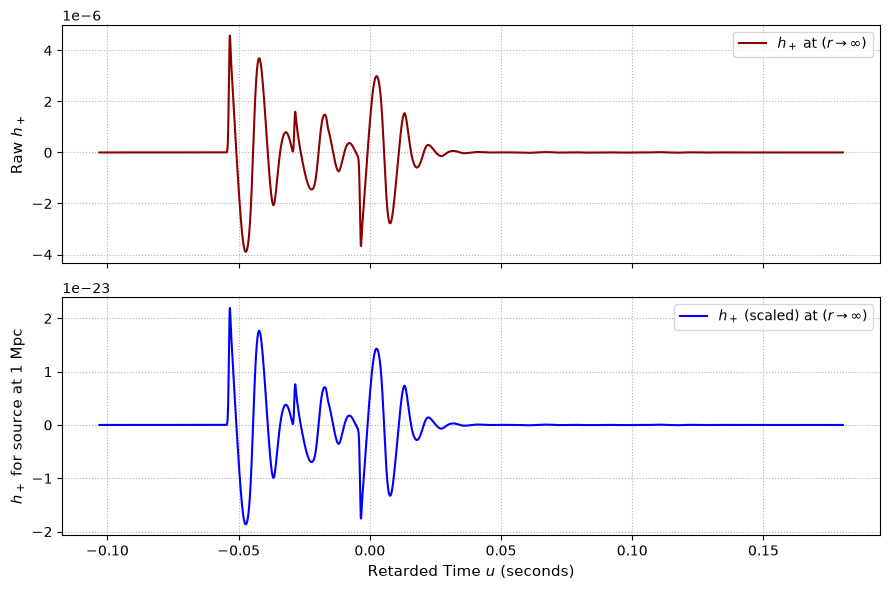

In [9]:
u_time, psi_even_inf = psi_at_infinity(t_sim, r_obs, psi_ext, l)
h_p_inf = h_plus_infinity(u_time, psi_even_inf, l, theta)
h_scaled = h_p_inf * (L_m / D_l)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax1.plot(
    u_time * t_m,
    h_p_inf,
    color='darkred',
    linewidth=1.5,
    label=r'$h_+$ at $(r \to \infty)$',
)

ax1.set_ylabel(r'Raw $h_+$', fontsize=11)
ax1.grid(True, linestyle=':', alpha=1)
ax1.legend(loc='upper right')

ax2.plot(
    u_time * t_m,
    h_scaled,
    color='blue',
    linewidth=1.5,
    label=r'$h_+$ (scaled) at $(r \to \infty)$',
)
ax2.set_ylabel(r'$h_+$ for source at 1 Mpc', fontsize=11)
ax2.grid(True, linestyle=':', alpha=1)
ax2.legend(loc='upper right')

plt.xlabel(r'Retarded Time $u$ (seconds)', fontsize=11)
plt.tight_layout()
plt.show()

In [10]:
# Time step in seconds (assuming uniform sampling)
dt = (u_time[1] - u_time[0]) * (G_SI * M_p / c_SI**3)

# Scaled strain at your chosen distance (e.g., 1 Mpc)
h_scaled = h_p_inf * (L_m / D_l)

# Compute FFT frequencies and values
freqs = np.fft.rfftfreq(len(h_scaled), d=dt)
fft_vals = np.fft.rfft(h_scaled) * dt

# Characteristic strain approximation for comparison
characteristic_strain = np.abs(freqs * fft_vals)

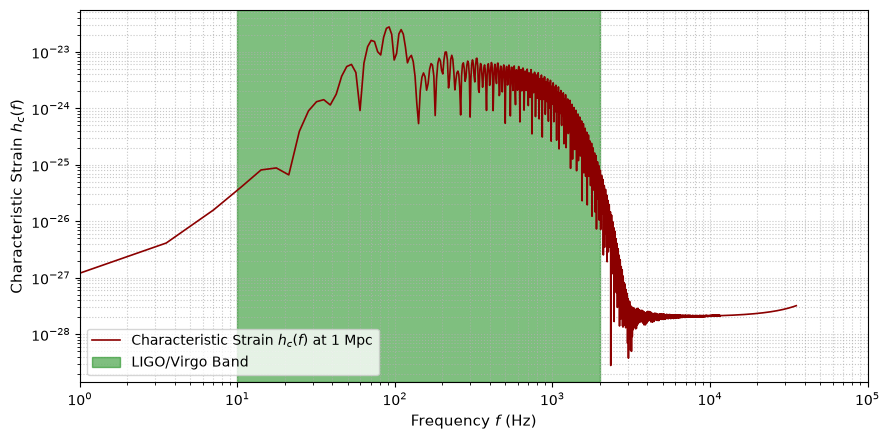

In [11]:
plt.figure(figsize=(9, 4.5))
plt.loglog(
    freqs,
    characteristic_strain,
    color='darkred',
    linewidth=1.2,
    label=r'Characteristic Strain $h_c(f)$ at $1\text{ Mpc}$',
)

# Highlighting the typical ground-based detector sweet spot (10 Hz to 2 kHz)
plt.axvspan(10, 2000, color='green', alpha=0.50, label='LIGO/Virgo Band')

plt.xlabel(r'Frequency $f$ (Hz)', fontsize=11)
plt.ylabel(r'Characteristic Strain $h_c(f)$', fontsize=11)
plt.grid(True, which='both', linestyle=':', alpha=0.7)
plt.xlim(1, 100000)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()